# Email Spam Classification using KNN and SVM

## 1. Import libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Load the dataset

In [ ]:
df = pd.read_csv("emails.csv")
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


## 3. Check the data

In [ ]:
df.shape

(5172, 3002)

In [ ]:
df.isnull().sum().sum()

0

In [ ]:
df["Prediction"].value_counts()

Prediction
0    3672
1    1500
Name: count, dtype: int64

## 4. Features and target

In [ ]:
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

## 5. Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 6. Scaling

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 7. KNN

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
print(classification_report(y_test, y_pred_knn, target_names=["Not Spam", "Spam"]))

              precision    recall  f1-score   support

    Not Spam       0.98      0.80      0.88       739
        Spam       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035



## 8. SVM

In [ ]:
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm,target_names=["Not Spam", "Spam"]))

SVM Accuracy: 0.9468599033816425
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.96       739
        Spam       0.90      0.92      0.91       296

    accuracy                           0.95      1035
   macro avg       0.93      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



## 9. Confusion matrix: KNN

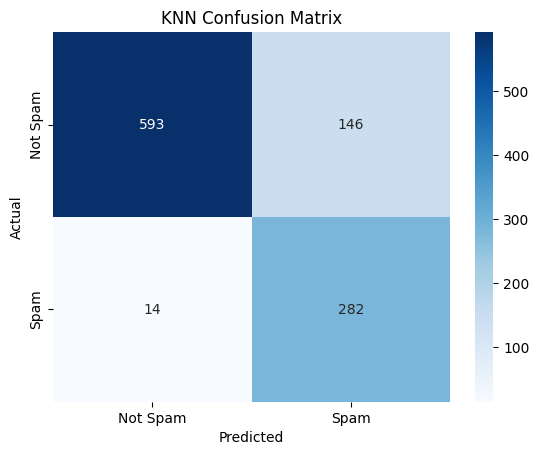

In [ ]:
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Spam", "Spam"], yticklabels=["Not Spam", "Spam"])
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

## 10. Confusion matrix: SVM

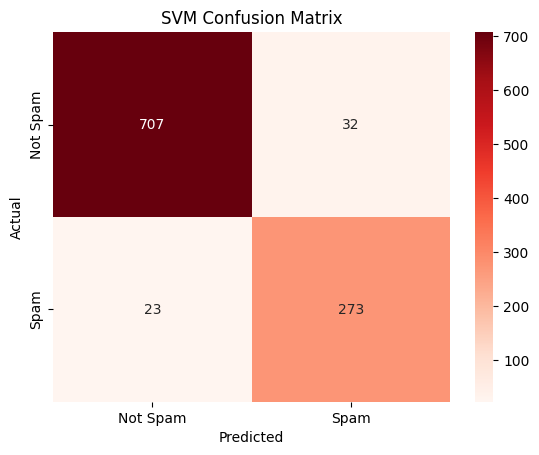

In [ ]:
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt="d", cmap="Reds",
            xticklabels=["Not Spam", "Spam"], yticklabels=["Not Spam", "Spam"])
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

## 11. Comparison

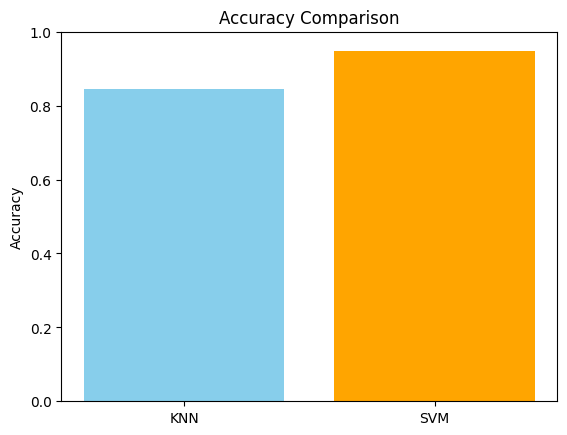

In [ ]:
acc_knn = accuracy_score(y_test, y_pred_knn)
acc_svm = accuracy_score(y_test, y_pred_svm)

plt.bar(["KNN", "SVM"], [acc_knn, acc_svm], color=["skyblue", "orange"])
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

## Conclusion
SVM gave higher accuracy than KNN for spam classification.